# Simulação de sistema de recomendação (com dados reduzidos via PCA)
___

### Importando bibliotecas/dados:

In [46]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

import time
from itertools import combinations

import matplotlib.pyplot as plt
import seaborn as sns

import random

In [47]:
df = pd.read_csv('../data/umap/df_umap_numerico.csv')
df_descritivo = pd.read_csv('../data/umap/df_umap_descritivo.csv')

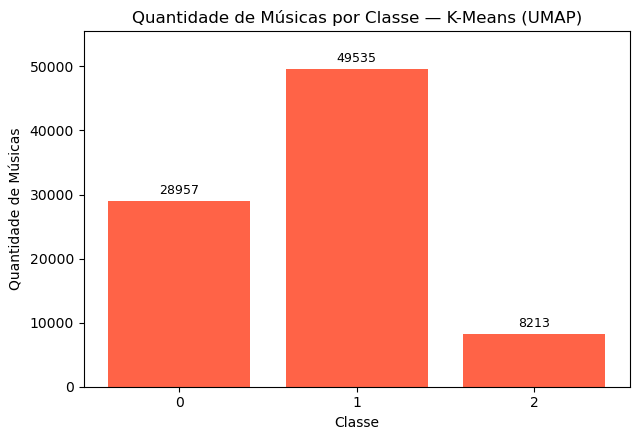

In [70]:
col_kmeans = "cluster_umap_kmeans" if "cluster_umap_kmeans" in df.columns else "kmeans_label"
counts_kmeans = df[col_kmeans].value_counts().sort_index()

plt.figure(figsize=(6.5, 4.5))
bars_km = plt.bar(counts_kmeans.index.astype(str), counts_kmeans.values, color='tomato')
plt.title("Quantidade de Músicas por Classe — K-Means (UMAP)")
plt.xlabel("Classe")
plt.ylabel("Quantidade de Músicas")
plt.bar_label(bars_km, fmt="%d", padding=3, fontsize=9)
plt.ylim(0, counts_kmeans.values.max() * 1.12)
plt.tight_layout()
plt.show()

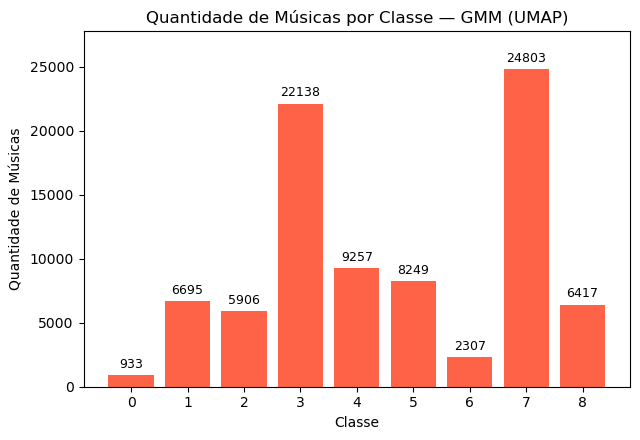

In [71]:
col_gmm = "cluster_umap_gmm" if "cluster_umap_gmm" in df.columns else "gmm_label"
counts_gmm = df[col_gmm].value_counts().sort_index()

plt.figure(figsize=(6.5, 4.5))
bars_gmm = plt.bar(counts_gmm.index.astype(str), counts_gmm.values, color='tomato')
plt.title("Quantidade de Músicas por Classe — GMM (UMAP)")
plt.xlabel("Classe")
plt.ylabel("Quantidade de Músicas")
plt.bar_label(bars_gmm, fmt="%d", padding=3, fontsize=9)
plt.ylim(0, counts_gmm.values.max() * 1.12)
plt.tight_layout()
plt.show()

In [48]:
cluster_cols = [
    c for c in [
        "cluster_umap_kmeans",
        "cluster_umap_gmm",
    ]
    if c in df.columns
]

y = df[cluster_cols].copy()

feature_cols = [c for c in df.columns if c not in cluster_cols]
X = df[feature_cols].to_numpy(dtype=float)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

df_scaled = pd.DataFrame(X_scaled, columns=feature_cols, index=df.index)
df_scaled

,popularity,duration_ms,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,mode
0,1.932530,0.000308,0.648376,-0.682910,-1.204468,0.338829,0.479250,-0.869304,-0.545775,0.709881,0.944713,-1.140340,0.224408,-1.314252
1,1.025884,-0.708542,-0.799051,-1.830529,-1.204468,-1.663314,-0.103475,1.765788,-0.545761,-0.597338,-0.759256,-1.487084,0.224408,0.760889
2,1.126623,-0.173196,-0.697279,-1.079714,-1.485576,-0.231521,-0.283447,-0.343941,-0.545778,-0.515955,-1.318370,-1.525556,0.224408,0.760889
3,1.831792,-0.250967,-1.669769,-2.244450,-1.485576,-1.907641,-0.452935,1.709647,-0.545562,-0.439658,-1.230890,1.979394,-1.986393,0.760889
4,2.385853,-0.277902,0.320443,-0.752934,-0.923359,-0.221404,-0.310530,0.421353,-0.545778,-0.689403,-1.139606,-0.075235,0.224408,0.760889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86700,-0.686669,1.349979,-2.201246,-1.562103,-0.080032,-1.502593,-0.401390,0.926624,2.289501,-0.672109,-1.645852,0.125802,2.435208,0.760889
86701,-0.636300,1.349988,-2.189938,-2.021151,-1.485576,-1.870037,-0.419737,1.972624,2.436154,-0.576992,-1.641668,-1.229387,0.224408,-1.314252
86702,-0.636300,0.357112,0.382637,-1.196421,-1.485576,-0.453133,-0.403137,1.597364,-0.545778,-0.684317,1.051211,0.338045,0.224408,-1.314252
86703,0.320715,0.465788,0.145169,-0.507849,0.482186,-0.451988,-0.510596,0.161330,-0.545778,0.262273,-0.203945,0.457151,0.224408,0.760889


### Simulação de um usuário
___
O usuário começa com 5 músicas selecionadas para mitigar o _cold-start_, simulando técnicas que plataformas costumam utilizar para esse fim.

In [49]:
rng = np.random.default_rng(seed=73)
musicas_usuario = rng.choice(len(df_scaled), size=5, replace=False)
musicas_usuario

array([70995,  2565, 67878, 26303, 42712])

In [50]:
# Calculando o vetor médio do usuário:
vetor_usuario = X_scaled[musicas_usuario].mean(axis=0)
vetor_usuario


array([ 0.14946012,  0.00709267, -0.28114374, -0.11960354, -0.13625376,
        0.02246443, -0.23347427, -0.12875426, -0.52553487, -0.48655518,
       -0.71665652,  0.16081578,  0.22440751, -0.06916738])

### TESTE INICIAL GLOBAL
___

In [51]:
X_scaled_np = df_scaled.to_numpy(dtype=float)
u_2d = np.asarray(vetor_usuario, dtype=float).reshape(1, -1)
excluded = set(int(i) for i in np.asarray(globals().get("user_seed_indices", [])).tolist())

n_runs = 10
tempos_global_umap = []

# Executa 10 vezes medindo o tempo de cada rodada
for _ in range(n_runs):
    t0 = time.perf_counter()

    sims = cosine_similarity(u_2d, X_scaled_np)[0]
    ranked_indices = np.argsort(sims)[::-1]
    top10_global_idx = np.array(
        [int(i) for i in ranked_indices if int(i) not in excluded][:10],
        dtype=int,
    )
    top10_global_scores = sims[top10_global_idx]

    tempos_global_umap.append(time.perf_counter() - t0)

tempo_execucao = float(np.mean(tempos_global_umap))
tempo_std_global_umap = float(np.std(tempos_global_umap, ddof=1)) if n_runs > 1 else 0.0

num_musicas_global = df_scaled.shape[0]

print("Top 10 índices:", top10_global_idx.tolist())
print("Top 10 similaridades:", np.round(top10_global_scores, 4).tolist())
print(
    f"Tempo médio ({n_runs} execuções): {tempo_execucao:.6f} s "
    f"({tempo_execucao * 1000:.2f} ms ± {tempo_std_global_umap * 1000:.2f} ms)"
)

Top 10 índices: [15866, 34455, 57037, 7771, 25873, 51482, 85838, 10934, 34355, 26313]
Top 10 similaridades: [0.8244, 0.8205, 0.8179, 0.8009, 0.7983, 0.7941, 0.7914, 0.7905, 0.7893, 0.7879]
Tempo médio (10 execuções): 0.018890 s (18.89 ms ± 1.89 ms)


### TESTE LOCAL (K-Means)
___


In [52]:
col_kmeans = "cluster_umap_kmeans"  # ajuste o nome se a coluna do K-Means tiver outro nome em `y`
labels_kmeans = y[col_kmeans].to_numpy()

# 1. Dicionário com os vetores médios (centroides) de cada cluster do K-Means em `df_scaled`
centroids_kmeans = {}
for c in np.sort(np.unique(labels_kmeans)):
    mask = labels_kmeans == c
    centroids_kmeans[int(c)] = df_scaled.loc[mask].mean(axis=0).to_numpy()

centroids_kmeans

{0: array([ 0.02986225,  0.03362718,  0.16371795,  0.16183107,  0.19881499,
         0.12629335,  0.0306346 , -0.18994505,  0.0341373 , -0.03971336,
         0.02093954,  0.01875109,  0.26723857, -1.31425204]),
 1: array([ 0.01303059,  0.00186379,  0.02994329,  0.02760412, -0.10587573,
         0.04665106, -0.04378141, -0.01281482, -0.06526339,  0.01389518,
         0.07141149,  0.01541154,  0.26573588,  0.75452141]),
 2: array([-0.18387819, -0.12980214, -0.75782562, -0.73706468, -0.06240492,
        -0.72664518,  0.15604844,  0.746989  ,  0.27326288,  0.05621358,
        -0.50453112, -0.15906319, -2.54494753,  0.08298774])}

In [53]:
u_2d = np.asarray(vetor_usuario, dtype=float).reshape(1, -1)

sim_kmeans = {}
for c, centroid in centroids_kmeans.items():
    c_2d = np.asarray(centroid, dtype=float).reshape(1, -1)
    sim_kmeans[c] = float(cosine_similarity(u_2d, c_2d)[0, 0])

# Ordena do maior para o menor score de similaridade
ranking_clusters = sorted(sim_kmeans.items(), key=lambda x: x[1], reverse=True)

for c, score in ranking_clusters:
    print(f"Cluster {c}: similaridade de cosseno = {score:.4f}")

best_cluster_kmeans = ranking_clusters[0][0]
print(f"\nCluster ideal (maior similaridade de cosseno): {best_cluster_kmeans}")

Cluster 0: similaridade de cosseno = 0.0454
Cluster 1: similaridade de cosseno = 0.0041
Cluster 2: similaridade de cosseno = -0.0807

Cluster ideal (maior similaridade de cosseno): 0


In [54]:
cluster_indices = np.flatnonzero(labels_kmeans == best_cluster_kmeans)
X_cluster = X_scaled_np[cluster_indices]

excluded = set(int(i) for i in np.asarray(globals().get("user_seed_indices", [])).tolist())

n_runs = 10
tempos_local_kmeans_umap = []

# Mede o tempo médio de execução do Top 10 exclusivamente dentro do melhor cluster em 10 execuções
for _ in range(n_runs):
    t0 = time.perf_counter()

    sims_local = cosine_similarity(u_2d, X_cluster)[0]
    ranked_local_pos = np.argsort(sims_local)[::-1]

    top10_local_idx = np.array(
        [
            int(cluster_indices[pos])
            for pos in ranked_local_pos
            if int(cluster_indices[pos]) not in excluded
        ][:10],
        dtype=int,
    )
    top10_local_scores_kmeans = sims_local[
        [int(np.flatnonzero(cluster_indices == idx)[0]) for idx in top10_local_idx]
    ]

    tempos_local_kmeans_umap.append(time.perf_counter() - t0)

tempo_execucao_local_kmeans = float(np.mean(tempos_local_kmeans_umap))
tempo_std_local_kmeans = float(np.std(tempos_local_kmeans_umap, ddof=1)) if n_runs > 1 else 0.0

num_musicas_kmeans = len(cluster_indices)

print(f"Melhor cluster (K-Means): {best_cluster_kmeans} ({len(cluster_indices)} músicas)")
print("Top 10 índices (local):", top10_local_idx.tolist())
print("Top 10 similaridades (local):", np.round(top10_local_scores_kmeans, 4).tolist())
print("Média de similaridade (local): ", np.round(top10_local_scores_kmeans.mean(), 4))
print(
    f"Tempo médio de execução (local, {n_runs} execuções): "
    f"{tempo_execucao_local_kmeans:.6f} s "
    f"({tempo_execucao_local_kmeans * 1000:.2f} ms ± {tempo_std_local_kmeans * 1000:.2f} ms)"
)

Melhor cluster (K-Means): 0 (28957 músicas)
Top 10 índices (local): [7771, 25873, 25263, 26182, 25432, 2710, 61574, 4534, 25838, 35446]
Top 10 similaridades (local): [0.8009, 0.7983, 0.7867, 0.7832, 0.7812, 0.7728, 0.7681, 0.7615, 0.7598, 0.7581]
Média de similaridade (local):  0.7771
Tempo médio de execução (local, 10 execuções): 0.013630 s (13.63 ms ± 3.16 ms)


### TESTE LOCAL (GMM)
___

In [55]:
col_gmm = "cluster_umap_gmm" 
labels_gmm = y[col_gmm].to_numpy()

centroids_gmm = {}
for c in np.sort(np.unique(labels_gmm)):
    mask = labels_gmm == c
    centroids_gmm[int(c)] = df_scaled.loc[mask].mean(axis=0).to_numpy()

centroids_gmm

{0: array([-0.13644048, -0.28927591, -0.22379399, -0.42671699, -0.050505  ,
         0.00862452,  0.72950102,  0.35709207, -0.49261345, -0.28439905,
        -0.09441142, -0.20657238,  2.43520775, -0.13322318]),
 1: array([ 0.07142734,  0.10842013,  0.04673681,  0.25821201,  0.13272063,
         0.21053818,  0.84202039, -0.00480324, -0.49431694,  1.53773359,
         0.16931925,  0.02993986,  0.26271264,  0.75004067]),
 2: array([-0.16871704, -0.15878753, -0.78239782, -0.77846896, -0.12058477,
        -0.76966423,  0.14867844,  0.77559279,  0.26070279,  0.0960563 ,
        -0.51064192, -0.21780734, -2.76313004,  0.62877713]),
 3: array([ 0.13300378, -0.04778649,  0.23489998,  0.24617964,  0.18398537,
         0.3000397 ,  0.07740051, -0.22291272, -0.48010178,  0.01512125,
         0.18305178,  0.0281028 ,  0.22700398, -1.31425204]),
 4: array([-0.3183048 ,  0.38999337, -0.27007587, -0.24778946, -0.15658762,
        -0.70076864, -0.18040877,  0.09666197,  1.81977476, -0.15392662,
       

In [56]:
u_2d = np.asarray(vetor_usuario, dtype=float).reshape(1, -1)

sim_gmm = {}
for c, centroid in centroids_gmm.items():
    c_2d = np.asarray(centroid, dtype=float).reshape(1, -1)
    sim_gmm[c] = float(cosine_similarity(u_2d, c_2d)[0, 0])

# Ordena do maior para o menor score de similaridade
ranking_clusters = sorted(sim_gmm.items(), key=lambda x: x[1], reverse=True)

for c, score in ranking_clusters:
    print(f"Cluster {c}: similaridade de cosseno = {score:.4f}")

best_cluster_gmm = ranking_clusters[0][0]
print(f"\nCluster ideal (maior similaridade de cosseno): {best_cluster_gmm}")

Cluster 0: similaridade de cosseno = 0.2805
Cluster 7: similaridade de cosseno = 0.2325
Cluster 3: similaridade de cosseno = 0.1003
Cluster 5: similaridade de cosseno = 0.0912
Cluster 6: similaridade de cosseno = -0.0188
Cluster 2: similaridade de cosseno = -0.0964
Cluster 8: similaridade de cosseno = -0.1166
Cluster 4: similaridade de cosseno = -0.1476
Cluster 1: similaridade de cosseno = -0.3607

Cluster ideal (maior similaridade de cosseno): 0


In [57]:
# Filtra apenas os índices do dataset pertencentes ao melhor cluster (GMM no UMAP)
cluster_indices = np.flatnonzero(labels_gmm == best_cluster_gmm)
X_cluster = X_scaled_np[cluster_indices]

excluded = set(int(i) for i in np.asarray(globals().get("user_seed_indices", [])).tolist())

n_runs = 10
tempos_local_gmm_umap = []

# Mede o tempo médio de execução do Top 10 exclusivamente dentro do melhor cluster em 10 execuções
for _ in range(n_runs):
    t0 = time.perf_counter()

    sims_local = cosine_similarity(u_2d, X_cluster)[0]
    ranked_local_pos = np.argsort(sims_local)[::-1]

    top10_local_idx_gmm = np.array(
        [
            int(cluster_indices[pos])
            for pos in ranked_local_pos
            if int(cluster_indices[pos]) not in excluded
        ][:10],
        dtype=int,
    )
    top10_local_scores_gmm = sims_local[
        [int(np.flatnonzero(cluster_indices == idx)[0]) for idx in top10_local_idx_gmm]
    ]

    tempos_local_gmm_umap.append(time.perf_counter() - t0)

tempo_execucao_local_gmm = float(np.mean(tempos_local_gmm_umap))
tempo_std_local_gmm = float(np.std(tempos_local_gmm_umap, ddof=1)) if n_runs > 1 else 0.0

num_musicas_gmm = len(cluster_indices)

print(f"Melhor cluster (GMM): {best_cluster_gmm} ({len(cluster_indices)} músicas)")
print("Top 10 índices (local):", top10_local_idx_gmm.tolist())
print("Top 10 similaridades (local):", np.round(top10_local_scores_gmm, 4).tolist())
print("Média de similaridade (local): ", np.round(top10_local_scores_gmm, 4).mean())
print(
    f"Tempo médio de execução (local, {n_runs} execuções): "
    f"{tempo_execucao_local_gmm:.6f} s "
    f"({tempo_execucao_local_gmm * 1000:.2f} ms ± {tempo_std_local_gmm * 1000:.2f} ms)"
)

Melhor cluster (GMM): 0 (933 músicas)
Top 10 índices (local): [435, 57778, 75910, 33459, 7879, 38005, 26241, 66648, 83481, 66723]
Top 10 similaridades (local): [0.6565, 0.6517, 0.6428, 0.6268, 0.6244, 0.6234, 0.6165, 0.6164, 0.6164, 0.6112]
Média de similaridade (local):  0.6286099999999999
Tempo médio de execução (local, 10 execuções): 0.000903 s (0.90 ms ± 0.29 ms)


### Cálculo do ILD 
___


In [58]:
def calcular_ild(df_features: pd.DataFrame, indices) -> float:
    """Calcula o Intra-List Distance (ILD) médio usando distância de cosseno."""
    idx_list = [int(i) for i in indices]
    if len(idx_list) < 2:
        return 0.0

    # Pega os vetores das músicas recomendadas no espaço escalonado
    vetores = df_features.iloc[idx_list].to_numpy(dtype=float)

    # Matriz de similaridade de cosseno entre as músicas da lista (shape: 10x10)
    sim_matrix = cosine_similarity(vetores)

    # Coleta a distância de cosseno (1 - sim) apenas para pares distintos (i < j)
    distancias = [
        1.0 - float(sim_matrix[i, j])
        for i, j in combinations(range(len(idx_list)), 2)
    ]

    return float(np.mean(distancias))

ild_local_kmeans = calcular_ild(df_scaled, top10_local_idx.tolist())
ild_global = calcular_ild(df_scaled, top10_global_idx.tolist())
ild_local_gmm = calcular_ild(df_scaled, top10_local_idx_gmm.tolist())

print(f'ILD global (Baseline): {ild_global:.4f}')
print(f'ILD local (K-Means): {ild_local_kmeans:.4f}')
print(f'ILD local (GMM): {ild_local_gmm:.4f}')

ILD global (Baseline): 0.2297
ILD local (K-Means): 0.1185
ILD local (GMM): 0.2239


### Resultados finais:
___


In [59]:
print(f'-' * 80)
print('RESULTADOS DO BASELINE')
print(f'-' * 80)
print(f'Número de músicas analisadas:           {num_musicas_global}')
print(f'Tempo de execução:                      {tempo_execucao:.6f}s ({tempo_execucao * 1000:.2f} ms)')
print(f'ILD calculado:                          {ild_global:.4f}')
print(f'Média de similaridade com o usuário:    {np.round(top10_global_scores.mean(), 4)}')
print(f'-' * 80)
print('\n\n')

print(f'-' * 80)
print('RESULTADOS DO K-MEANS')
print(f'-' * 80)
print(f'Número de músicas analisadas:           {num_musicas_kmeans}')
print(f'Tempo de execução:                      {tempo_execucao_local_kmeans:.6f}s ({tempo_execucao_local_kmeans * 1000:.2f} ms)')
print(f'ILD calculado:                          {ild_local_kmeans:.4f}')
print(f'Média de similaridade com o usuário:    {np.round(top10_local_scores_kmeans.mean(), 4)}')
print(f'-' * 80)
print('\n\n')

print(f'-' * 80)
print('RESULTADOS DO GMM')
print(f'-' * 80)
print(f'Número de músicas analisadas:           {num_musicas_gmm}')
print(f'Tempo de execução:                      {tempo_execucao_local_gmm:.6f}s ({tempo_execucao_local_gmm * 1000:.2f} ms)')
print(f'ILD calculado:                          {ild_local_gmm:.4f}')
print(f'Média de similaridade com o usuário:    {np.round(top10_local_scores_gmm.mean(), 4)}')
print(f'-' * 80)
print('\n\n')

--------------------------------------------------------------------------------
RESULTADOS DO BASELINE
--------------------------------------------------------------------------------
Número de músicas analisadas:           86705
Tempo de execução:                      0.018890s (18.89 ms)
ILD calculado:                          0.2297
Média de similaridade com o usuário:    0.8015
--------------------------------------------------------------------------------



--------------------------------------------------------------------------------
RESULTADOS DO K-MEANS
--------------------------------------------------------------------------------
Número de músicas analisadas:           28957
Tempo de execução:                      0.013630s (13.63 ms)
ILD calculado:                          0.1185
Média de similaridade com o usuário:    0.7771
--------------------------------------------------------------------------------



-------------------------------------------------------------

         Global  K-Means  GMM
Global      1.0      0.2  0.0
K-Means     0.2      1.0  0.0
GMM         0.0      0.0  1.0


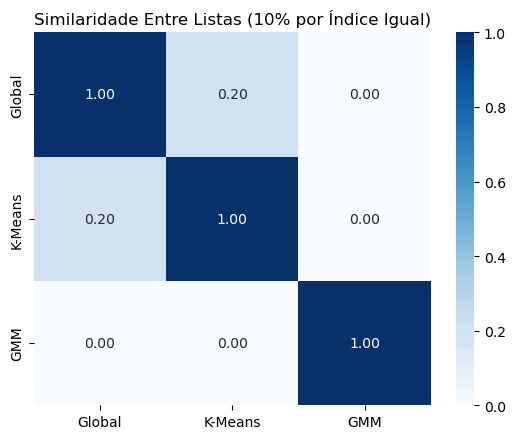

In [60]:
# Vetores de índices Top-10 (ajuste o nome da variável do GMM se estiver diferente no seu notebook)
listas_indices = {
    "Global": top10_global_idx,
    "K-Means": top10_local_idx,
    "GMM": top10_local_idx_gmm,
}

nomes = list(listas_indices.keys())
n = len(nomes)
matriz_sim = np.zeros((n, n), dtype=float)

# Cada índice igual entre duas listas soma 10% (0.10) de similaridade (até 1.00 = 100%)
for i, ni in enumerate(nomes):
    set_i = set(int(x) for x in np.asarray(listas_indices[ni]).tolist())
    for j, nj in enumerate(nomes):
        set_j = set(int(x) for x in np.asarray(listas_indices[nj]).tolist())
        iguais = len(set_i.intersection(set_j))
        matriz_sim[i, j] = iguais * 0.10

df_matriz = pd.DataFrame(matriz_sim, index=nomes, columns=nomes)
print(df_matriz.round(2))

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    df_matriz,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0.0,
    vmax=1.0,
)
plt.title("Similaridade Entre Listas (10% por Índice Igual)")
plt.tight_layout()
plt.show()